# 01 Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [2]:
df = pd.read_csv("../data/raw/HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [4]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [5]:
df.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
(df.select_dtypes(include="number") < 0).any()

Age                         False
DailyRate                   False
DistanceFromHome            False
Education                   False
EmployeeCount               False
EmployeeNumber              False
EnvironmentSatisfaction     False
HourlyRate                  False
JobInvolvement              False
JobLevel                    False
JobSatisfaction             False
MonthlyIncome               False
MonthlyRate                 False
NumCompaniesWorked          False
PercentSalaryHike           False
PerformanceRating           False
RelationshipSatisfaction    False
StandardHours               False
StockOptionLevel            False
TotalWorkingYears           False
TrainingTimesLastYear       False
WorkLifeBalance             False
YearsAtCompany              False
YearsInCurrentRole          False
YearsSinceLastPromotion     False
YearsWithCurrManager        False
dtype: bool

In [7]:
df.select_dtypes(include="number").columns.size

26

In [8]:
numeric_feats = df.select_dtypes(include="number").columns.values

In [9]:
ordinal_feats = [
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "WorkLifeBalance",
    "Education"
]

In [10]:
numeric_feats = list(set(numeric_feats) - set(ordinal_feats))

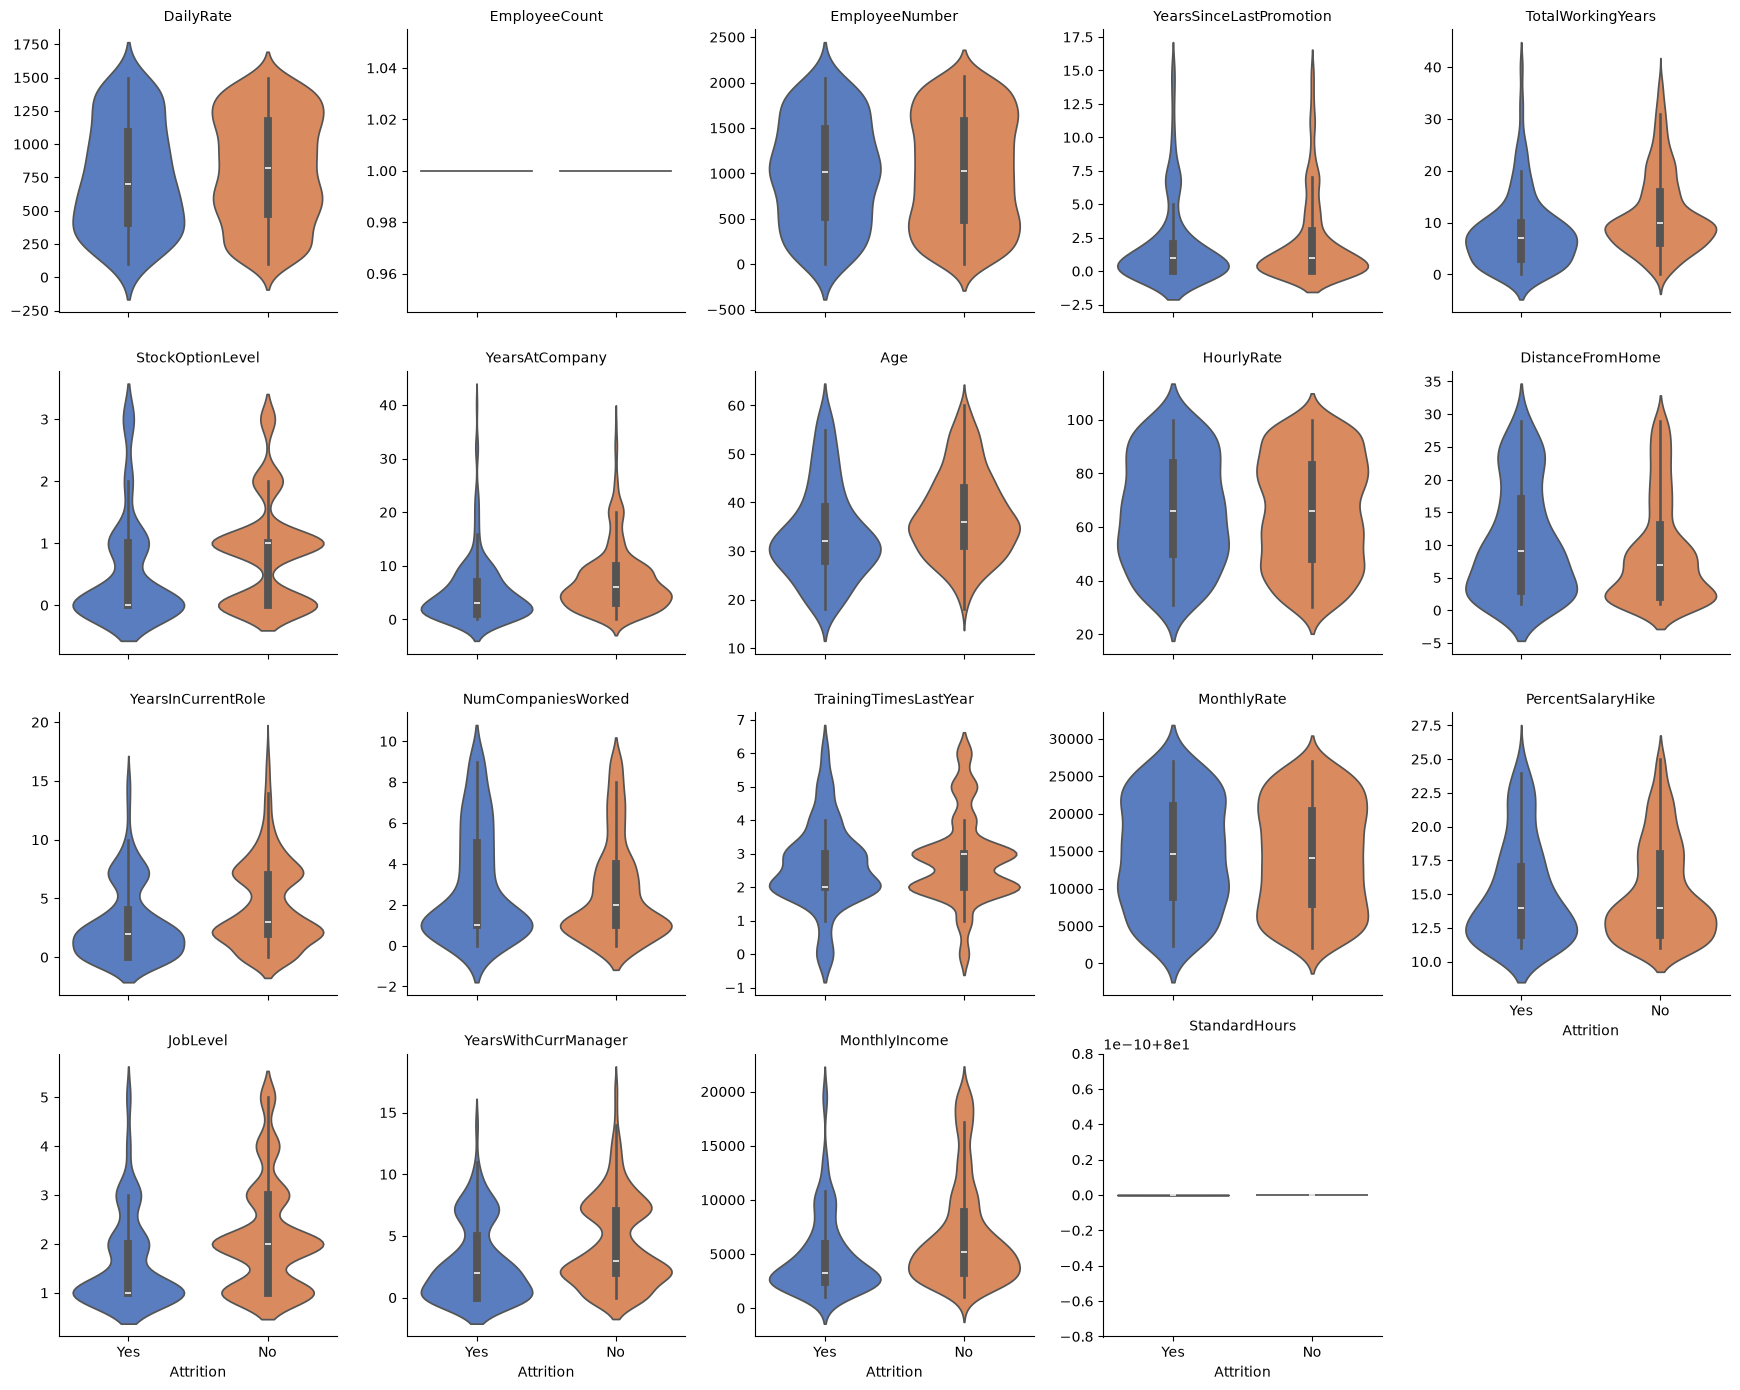

In [11]:
df_melt = df[numeric_feats + ["Attrition"]].melt(
    id_vars="Attrition", var_name="feature", value_name="value"
)

g = sns.catplot(
    data=df_melt,
    x="Attrition", y="value",
    col="feature", col_wrap=5,
    kind="violin",
    hue="Attrition",
    palette="muted",
    sharey=False,
    height=3.5, aspect=1
)

g.set_titles("{col_name}")
g.set_axis_labels("Attrition", "")
plt.tight_layout()
plt.show()

In [12]:
df[ordinal_feats].describe()

,EnvironmentSatisfaction,JobInvolvement,JobSatisfaction,PerformanceRating,RelationshipSatisfaction,WorkLifeBalance,Education
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,2.721769,2.729932,2.728571,3.153741,2.712245,2.761224,2.912925
std,1.093082,0.711561,1.102846,0.360824,1.081209,0.706476,1.024165
min,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,4.000000,3.000000,4.000000,3.000000,4.000000,3.000000,4.000000
max,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000


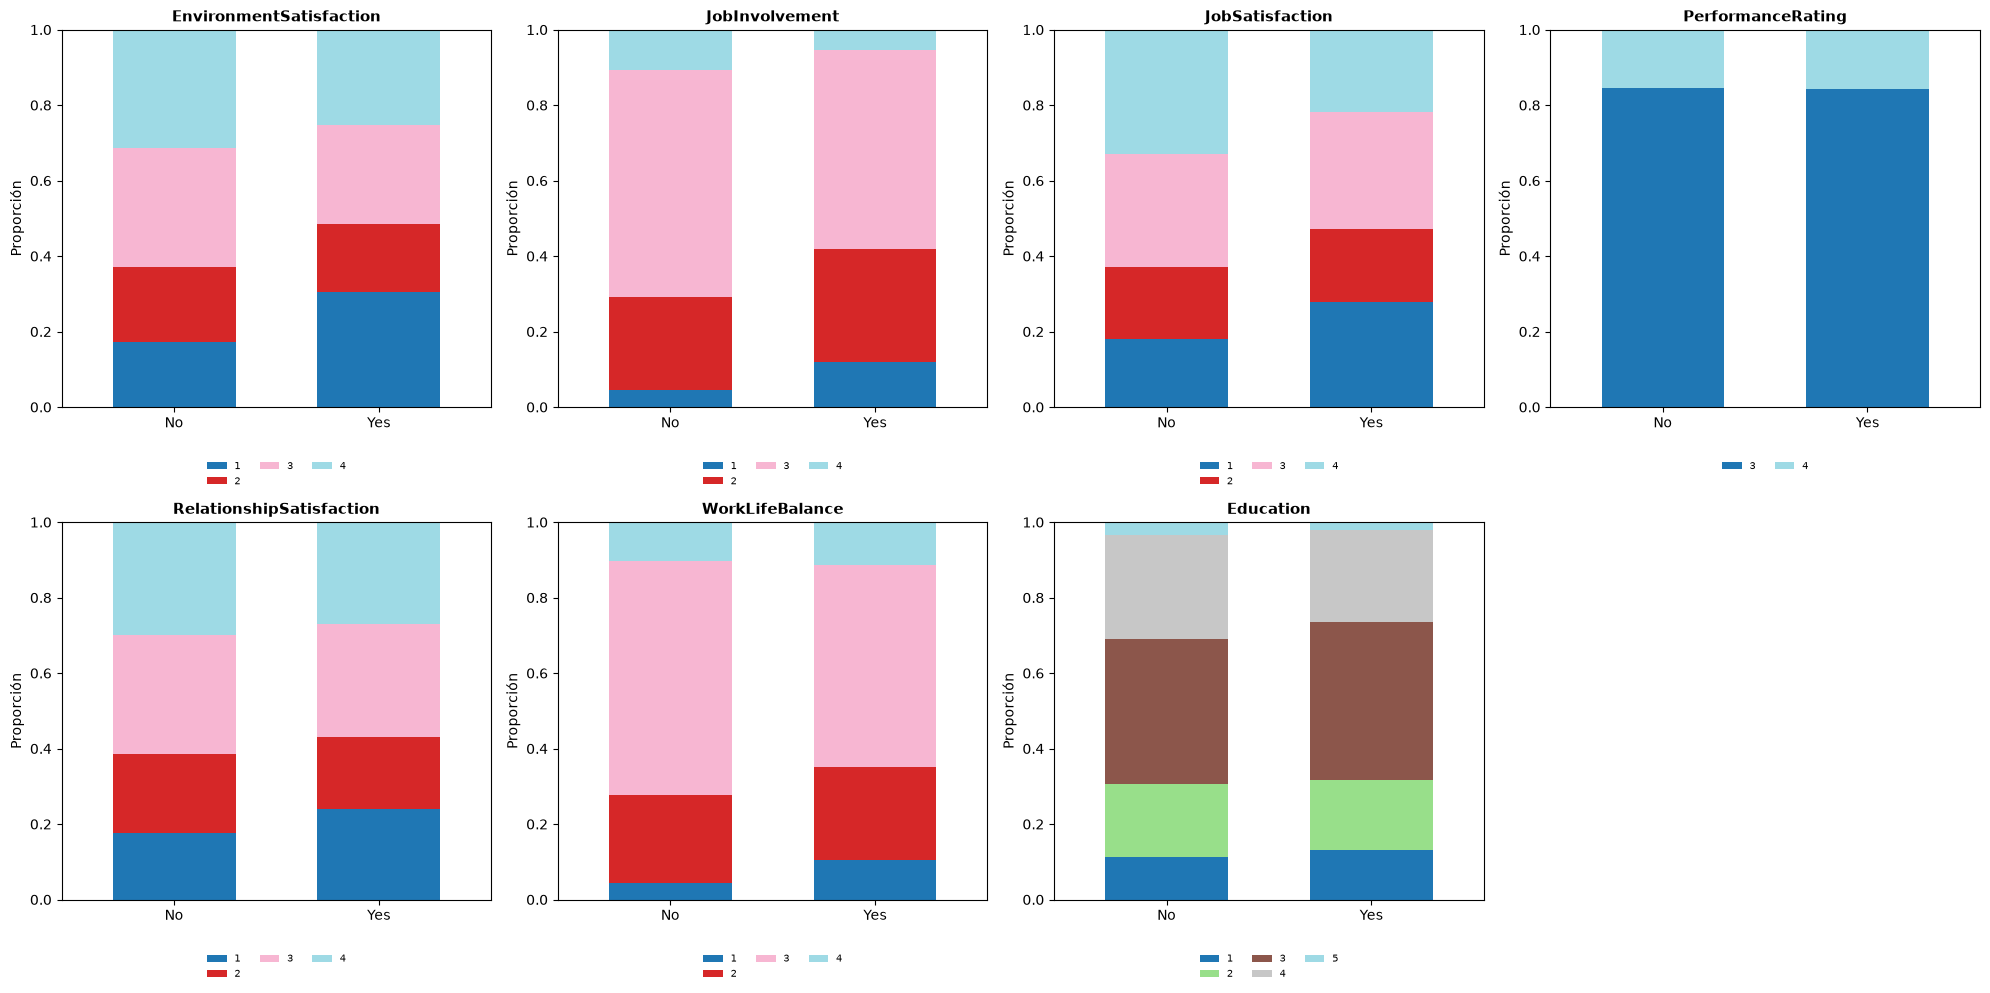

In [13]:
n_feats = len(ordinal_feats)
n_cols = 4
n_rows = math.ceil(n_feats / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()

for i, feat in enumerate(ordinal_feats):
    ct = pd.crosstab(df["Attrition"], df[feat], normalize="index")

    ct.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="tab20",
        width=0.6,
        legend=False
    )

    axes[i].set_title(feat, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Proporción")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=0)

    axes[i].legend(
        fontsize=7,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=min(len(ct.columns), 3),
        frameon=False
    )

for j in range(n_feats, len(axes)):
    fig.delaxes(axes[j])

# fig.suptitle("Distribución de Attrition por categoría (100% Stacked Bar)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [14]:
df.select_dtypes(include="str").columns

Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')

In [15]:
for col in df.select_dtypes(include="str").columns.values:
    print(df[col].value_counts())
    print(f"=================")

Attrition
No     1233
Yes     237
Name: count, dtype: int64
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
Gender
Male      882
Female    588
Name: count, dtype: int64
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64
MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64
Over18
Y    1470
Name: count,

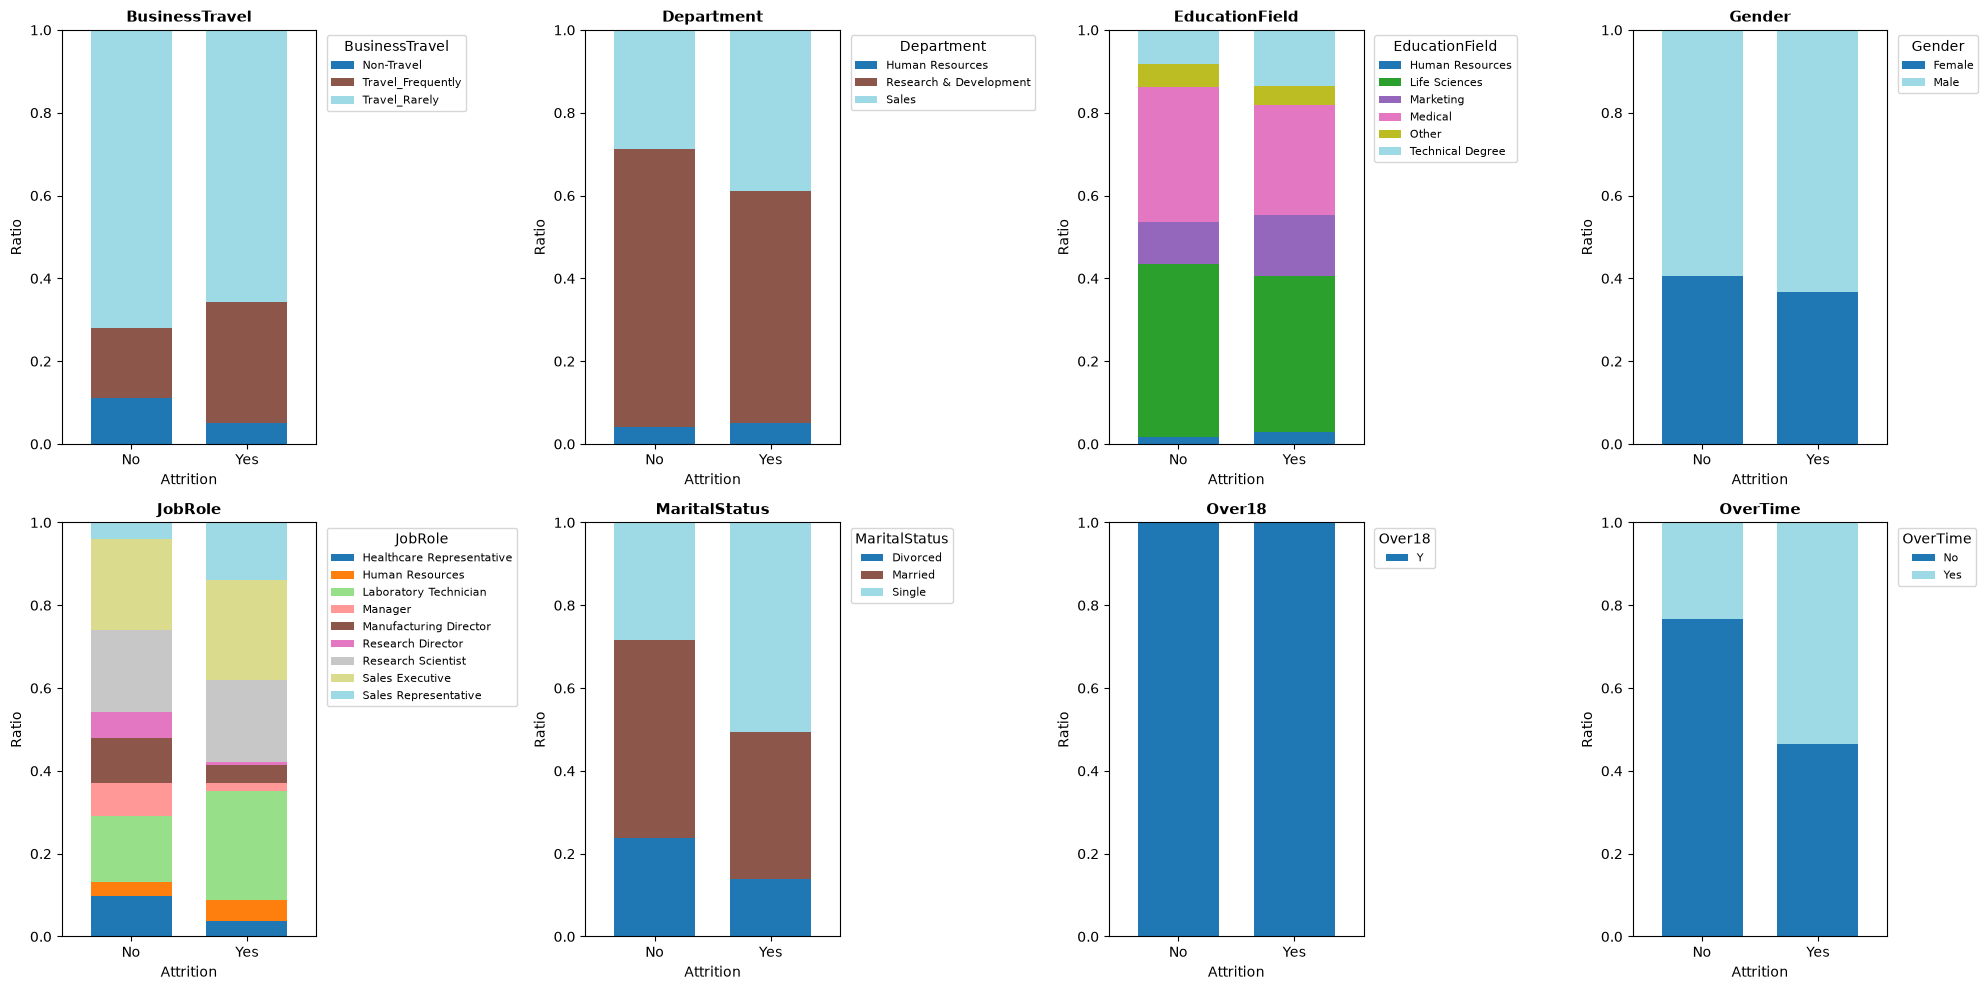

In [16]:
n_rows, n_cols = 2, 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()

features = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "Over18",
    "OverTime",
]

for i, feat in enumerate(features):
    ct = pd.crosstab(df["Attrition"], df[feat], normalize="index")

    ct.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        colormap="tab20",
        width=0.7
    )

    axes[i].set_title(feat, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Attrition")
    axes[i].set_ylabel("Ratio")
    axes[i].set_ylim(0, 1)
    axes[i].legend(
        title=feat,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )
    axes[i].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

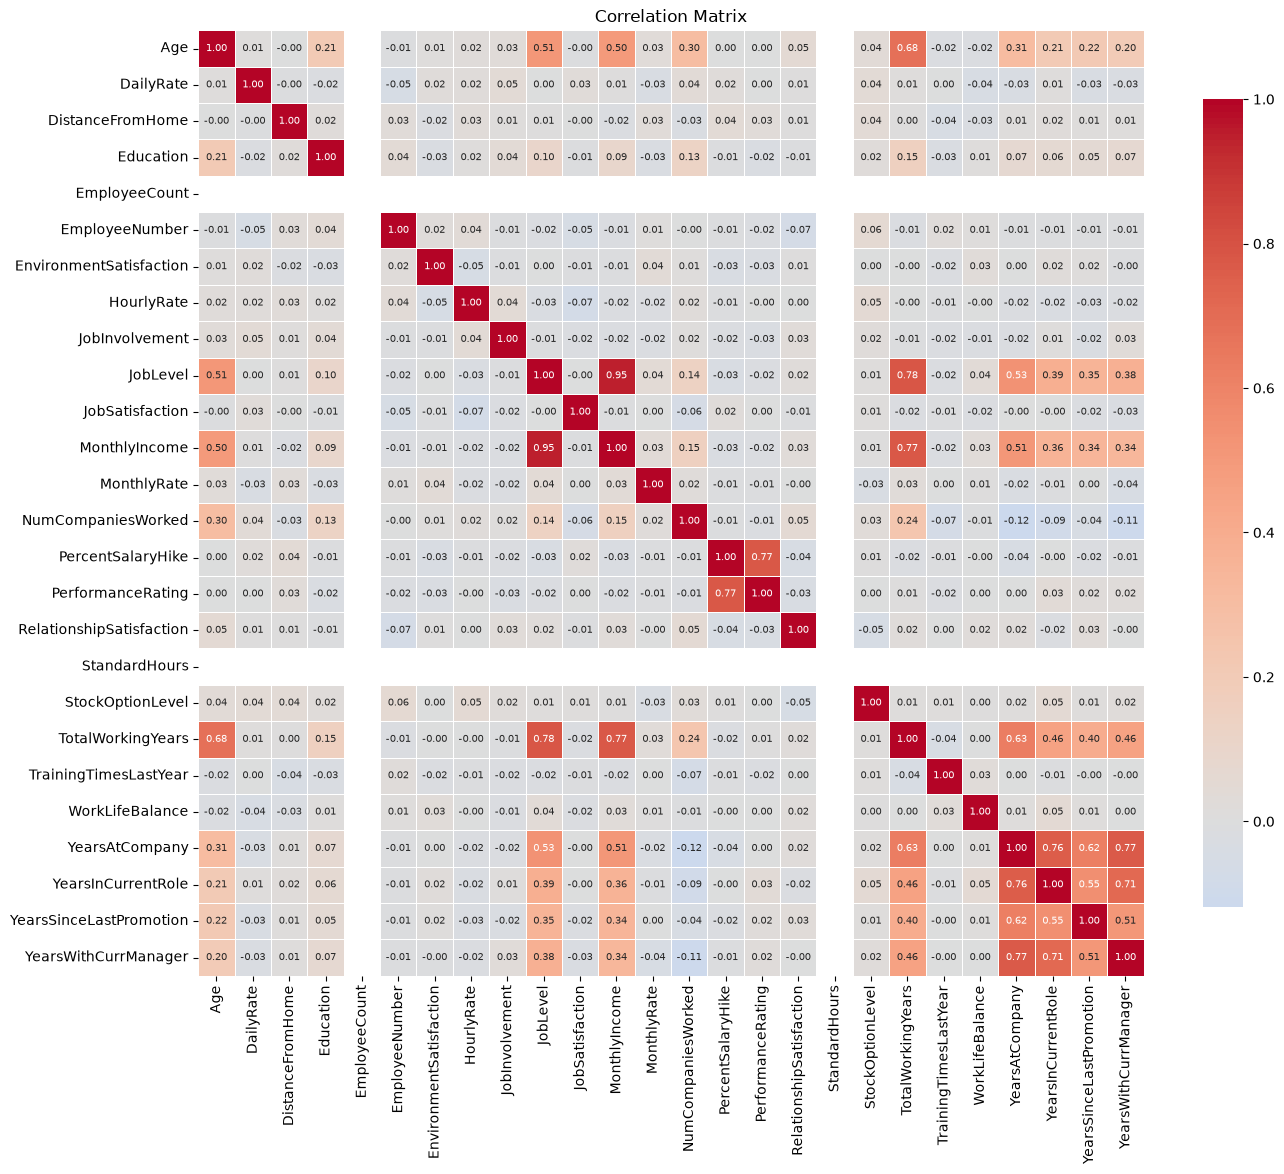

In [17]:
num_df = df.select_dtypes(include="number")

corr = num_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [18]:
X = num_df.drop(columns=["Attrition", "EmployeeCount", "StandardHours"], errors="ignore")
X = add_constant(X)

vif_data = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif_data = vif_data[vif_data["feature"] != "const"].sort_values("VIF", ascending=False)
vif_data

,feature,VIF
9,JobLevel,11.208731
11,MonthlyIncome,10.802169
18,TotalWorkingYears,4.767805
21,YearsAtCompany,4.587405
24,YearsWithCurrManager,2.774625
22,YearsInCurrentRole,2.718616
14,PercentSalaryHike,2.516413
15,PerformanceRating,2.514405
1,Age,2.044997
23,YearsSinceLastPromotion,1.674285
